# Assignment 07 | Statistical Validation



## 1. Imports and database connection


In [15]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data' / 'raw' / 'airtel.db').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DB_PATH = PROJECT_ROOT / 'data' / 'raw' / 'airtel.db'
START_DATE, END_DATE, ALPHA = '2025-01-01', '2025-07-01', 0.05
conn = sqlite3.connect(DB_PATH)
def q(sql): return pd.read_sql_query(sql, conn)
print('Database:', DB_PATH)

Database: C:\Users\safra\airtel-telecom-analytics\data\raw\airtel.db


## 2. Schema, counts, and data quality

In [16]:
for table in ['customer_features', 'recharges']:
    print('Schema:', table)
    display(q(f'PRAGMA table_info({table})')[['name','type']])

customer_quality = q("""SELECT COUNT(*) AS total_rows, COUNT(DISTINCT customer_id) AS unique_subscribers,
       SUM(customer_id IS NULL) AS missing_customer_ids,
       COUNT(*)-COUNT(DISTINCT customer_id) AS duplicate_id_rows
FROM customer_features""")
recharge_quality = q(f"""SELECT COUNT(*) AS all_recharge_rows,
       SUM(customer_id IS NULL) AS missing_customer_ids,
       SUM(recharge_date IS NULL) AS missing_dates,
       SUM(amount_inr IS NULL) AS missing_amounts,
       SUM(amount_inr <= 0) AS nonpositive_amounts,
       SUM(recharge_date >= '{START_DATE}' AND recharge_date < '{END_DATE}') AS in_window_rows,
       SUM(recharge_date < '{START_DATE}' OR recharge_date >= '{END_DATE}') AS outside_window_rows,
       MIN(recharge_date) AS source_first_date, MAX(recharge_date) AS source_last_date
FROM recharges""")
display(customer_quality)
display(recharge_quality)

Schema: customer_features


,name,type
0,customer_id,INT
1,activation_date,TEXT
2,tenure_days,INT
3,tenure_years,INT
4,observed_days,INT
5,circle_name,TEXT
6,region,TEXT
7,plan_name,TEXT
8,plan_type,TEXT
9,price_inr,INT


Schema: recharges


,name,type
0,recharge_id,INTEGER
1,customer_id,INTEGER
2,recharge_date,TEXT
3,amount_inr,INTEGER
4,plan_id,INTEGER
5,channel,TEXT
6,txn_type,TEXT


,total_rows,unique_subscribers,missing_customer_ids,duplicate_id_rows
0,22000,22000,0,0


,all_recharge_rows,missing_customer_ids,missing_dates,missing_amounts,nonpositive_amounts,in_window_rows,outside_window_rows,source_first_date,source_last_date
0,408089,0,0,0,0,83693,324396,2022-01-01,2025-06-27


## 3. One row per subscriber


In [17]:
validation_df = q(f"""WITH filtered AS (
    SELECT customer_id, recharge_date, amount_inr, strftime('%Y-%m',recharge_date) AS month
    FROM recharges WHERE recharge_date >= '{START_DATE}' AND recharge_date < '{END_DATE}'
), summary AS (
    SELECT customer_id, COUNT(*) AS recharge_count, SUM(amount_inr) AS total_recharge,
           AVG(amount_inr) AS average_recharge, COUNT(DISTINCT month) AS active_recharge_months
    FROM filtered GROUP BY customer_id
)
SELECT c.customer_id, c.is_churned, c.connection_type, c.tenure_days, c.complaint_count,
       COALESCE(s.recharge_count,0) AS recharge_count,
       COALESCE(s.total_recharge,0) AS total_recharge,
       s.average_recharge, COALESCE(s.active_recharge_months,0) AS active_recharge_months
FROM customer_features c LEFT JOIN summary s ON c.customer_id=s.customer_id""")
quality_summary = pd.DataFrame([{'rows':len(validation_df), 'unique_customer_ids':validation_df.customer_id.nunique(),
    'duplicate_customer_ids':int(validation_df.customer_id.duplicated().sum()),
    'no_recharge_subscribers':int((validation_df.recharge_count==0).sum())}])
display(validation_df.head())
display(quality_summary)
assert validation_df.customer_id.is_unique
assert validation_df.is_churned.notna().all()
assert len(validation_df)==int(customer_quality.loc[0,'unique_subscribers'])

,customer_id,is_churned,connection_type,tenure_days,complaint_count,recharge_count,total_recharge,average_recharge,active_recharge_months
0,9,0,Prepaid,1030,3,5,1745,349.0,5
1,31,0,Prepaid,506,0,2,1438,719.0,2
2,151,0,Prepaid,1074,4,6,2094,349.0,5
3,186,0,Prepaid,1273,0,2,1438,719.0,2
4,207,1,Prepaid,198,3,2,418,209.0,2


,rows,unique_customer_ids,duplicate_customer_ids,no_recharge_subscribers
0,22000,22000,0,3711


## 4. Test plan and reporting helpers


In [18]:
CHURNED = validation_df[validation_df.is_churned==1]
RETAINED = validation_df[validation_df.is_churned==0]
results=[]
def describe(x):
    x=pd.Series(x).dropna().astype(float)
    return {'n':len(x),'mean':x.mean(),'median':x.median(),'sd':x.std(ddof=1)}
def welch(test_id, question, col, unit, a=None, b=None, name_a='Churned', name_b='Retained'):
    a=(CHURNED if a is None else a)[col].dropna().astype(float)
    b=(RETAINED if b is None else b)[col].dropna().astype(float)
    stat,p=stats.ttest_ind(a,b,equal_var=False,alternative='two-sided')
    da,db=describe(a),describe(b); diff=da['mean']-db['mean']
    decision='Reject H0' if p<ALPHA else 'Fail to reject H0'
    direction='higher' if diff>0 else 'lower'
    business=(f'{name_a} mean was {abs(diff):,.2f} {unit} {direction} than {name_b}. ' +
       ('The difference is statistically detectable; practical value depends on costs and achievable effects.' if p<ALPHA else 'The data do not establish a mean difference; this does not prove the groups are identical.'))
    row={'Test ID':test_id,'Research Question':question,'Group 1':name_a,'Group 2':name_b,
      'Sample Size 1':da['n'],'Sample Size 2':db['n'],
      'Group Values':f"mean {da['mean']:,.2f} (median {da['median']:,.2f}, SD {da['sd']:,.2f}) vs mean {db['mean']:,.2f} (median {db['median']:,.2f}, SD {db['sd']:,.2f})",
      'Difference':diff,'Test Used':"Welch's independent-samples t-test, two-tailed",'Test Statistic':stat,'p-value':p,
      'Significance Level':ALPHA,'Decision':decision,'Business Interpretation':business,
      'H0':'The group population means are equal.','H1':'The group population means differ.',
      'Test Direction':'Two-tailed','Reason for Test':'Independent subscriber groups; Welch method allows unequal variances.','Unit':unit}
    results.append(row); return row
def distribution_check(col):
    out=[]
    for label,g in [('Churned',CHURNED),('Retained',RETAINED)]:
        x=g[col].dropna(); q1,q3=x.quantile(.25),x.quantile(.75)
        out.append({'Group':label,'Variable':col,'Skewness':x.skew(),'Median':x.median(),'P95':x.quantile(.95),'Maximum':x.max(),'Above 1.5 IQR':int((x>q3+1.5*(q3-q1)).sum())})
    return pd.DataFrame(out)

## 5. Recharge behaviour comparisons
One subscriber contributes one value to each test. Average transaction amount is calculated only among subscribers with at least one transaction; for others it is undefined.

In [19]:
total_result=welch('T1','Do total six-month recharge amounts differ by churn status?','total_recharge','INR')
count_result=welch('T2','Do six-month transaction counts differ by churn status?','recharge_count','transactions')
active_churned=CHURNED[CHURNED.recharge_count>0]
active_retained=RETAINED[RETAINED.recharge_count>0]
average_result=welch('T3','Among recharge-active subscribers, do average transaction amounts differ by churn status?','average_recharge','INR per transaction',active_churned,active_retained)
for col in ['total_recharge','recharge_count','average_recharge']:
    display(distribution_check(col))
display(pd.DataFrame([total_result,count_result,average_result]).set_index('Test ID'))

,Group,Variable,Skewness,Median,P95,Maximum,Above 1.5 IQR
0,Churned,total_recharge,3.078538,563.0,3541.25,10689,402
1,Retained,total_recharge,1.788570,1495.0,9893.70,10939,2920


,Group,Variable,Skewness,Median,P95,Maximum,Above 1.5 IQR
0,Churned,recharge_count,1.310790,1.0,5.0,12,116
1,Retained,recharge_count,0.248987,5.0,7.0,13,60


,Group,Variable,Skewness,Median,P95,Maximum,Above 1.5 IQR
0,Churned,average_recharge,1.712831,399.0,1672.666667,1871.000000,383
1,Retained,average_recharge,1.404116,479.0,1682.833333,1823.166667,1306


,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Group Values,Difference,Test Used,Test Statistic,p-value,Significance Level,Decision,Business Interpretation,H0,H1,Test Direction,Reason for Test,Unit
Test ID,,,,,,,,,,,,,,,,,,
T1,Do total six-month recharge amounts differ by ...,Churned,Retained,5226,16774,"mean 928.08 (median 563.00, SD 1,391.84) vs me...",-1493.478058,"Welch's independent-samples t-test, two-tailed",-53.214114,0.000000e+00,0.05,Reject H0,"Churned mean was 1,493.48 INR lower than Retai...",The group population means are equal.,The group population means differ.,Two-tailed,Independent subscriber groups; Welch method al...,INR
T2,Do six-month transaction counts differ by chur...,Churned,Retained,5226,16774,"mean 2.02 (median 1.00, SD 2.13) vs mean 4.36 ...",-2.346012,"Welch's independent-samples t-test, two-tailed",-64.180227,0.000000e+00,0.05,Reject H0,Churned mean was 2.35 transactions lower than ...,The group population means are equal.,The group population means differ.,Two-tailed,Independent subscriber groups; Welch method al...,transactions
T3,"Among recharge-active subscribers, do average ...",Churned,Retained,3582,14707,"mean 515.47 (median 399.00, SD 426.12) vs mean...",-78.152358,"Welch's independent-samples t-test, two-tailed",-9.821620,1.391981e-22,0.05,Reject H0,Churned mean was 78.15 INR per transaction low...,The group population means are equal.,The group population means differ.,Two-tailed,Independent subscriber groups; Welch method al...,INR per transaction


## 6. Recharge-frequency bands and churn
H0: low- and high-frequency churn proportions are equal. H1: they differ. A two-proportion z-test is two-tailed because neither direction is assumed. Categories count transactions for each subscriber.

In [20]:
validation_df['frequency_category']=pd.cut(validation_df.recharge_count,[-1,2,5,np.inf],labels=['Low frequency','Medium frequency','High frequency'])
frequency_summary=validation_df.groupby('frequency_category',observed=False).agg(subscribers=('customer_id','size'),churned=('is_churned','sum')).reset_index()
frequency_summary['churn_percent']=100*frequency_summary.churned/frequency_summary.subscribers
display(frequency_summary)
low=validation_df[validation_df.frequency_category=='Low frequency']; high=validation_df[validation_df.frequency_category=='High frequency']
n1,k1=len(low),int(low.is_churned.sum()); n2,k2=len(high),int(high.is_churned.sum())
p1,p2=k1/n1,k2/n2; pooled=(k1+k2)/(n1+n2)
z=(p1-p2)/np.sqrt(pooled*(1-pooled)*(1/n1+1/n2)); p=2*stats.norm.sf(abs(z)); pp=100*(p1-p2)
freq_result={'Test ID':'T4','Research Question':'Does churn percentage differ between low- and high-frequency subscribers?',
 'Group 1':'Low frequency (0-2)','Group 2':'High frequency (6+)','Sample Size 1':n1,'Sample Size 2':n2,
 'Group Values':f'{100*p1:.2f}% ({k1}/{n1}) vs {100*p2:.2f}% ({k2}/{n2})','Difference':pp,
 'Test Used':'Two-proportion z-test, two-tailed','Test Statistic':z,'p-value':p,'Significance Level':ALPHA,
 'Decision':'Reject H0' if p<ALPHA else 'Fail to reject H0',
 'Business Interpretation':f'Low-frequency churn differed from high-frequency churn by {pp:.2f} percentage points. This observational association cannot show that increasing recharge frequency would change churn.',
 'H0':'Low- and high-frequency population churn proportions are equal.','H1':'The proportions differ.',
 'Test Direction':'Two-tailed','Reason for Test':'Independent subscriber groups and binary churn outcome; pooled two-proportion z-test.','Unit':'percentage points'}
results.append(freq_result); display(pd.DataFrame([freq_result]).set_index('Test ID'))

,frequency_category,subscribers,churned,churn_percent
0,Low frequency,8812,3413,38.731276
1,Medium frequency,5147,1567,30.444919
2,High frequency,8041,246,3.059321


,Research Question,Group 1,Group 2,Sample Size 1,Sample Size 2,Group Values,Difference,Test Used,Test Statistic,p-value,Significance Level,Decision,Business Interpretation,H0,H1,Test Direction,Reason for Test,Unit
Test ID,,,,,,,,,,,,,,,,,,
T4,Does churn percentage differ between low- and ...,Low frequency (0-2),High frequency (6+),8812,8041,38.73% (3413/8812) vs 3.06% (246/8041),35.671955,"Two-proportion z-test, two-tailed",56.103292,0.0,0.05,Reject H0,Low-frequency churn differed from high-frequen...,Low- and high-frequency population churn propo...,The proportions differ.,Two-tailed,Independent subscriber groups and binary churn...,percentage points


## 7. Tenure comparison and visual
H0: mean tenure is equal for churned and retained subscribers. H1: means differ. Welch's test is two-tailed at alpha 0.05. The box plot shows medians and spread; its shape helps assess whether the mean alone tells the story.

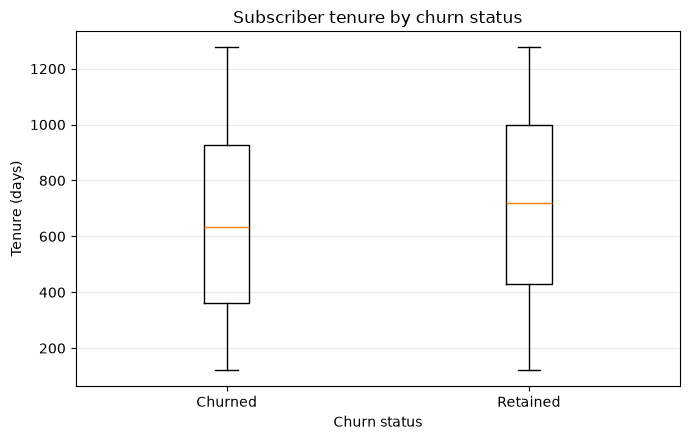

Tenure skewness, churned then retained: 0.15654603578923876 -0.04461893359074261


In [21]:
tenure_result=welch('T5','Does subscriber tenure differ by churn status?','tenure_days','days')
tenure_result['Business Interpretation'] += ' This association does not establish that tenure causes churn.'
fig,ax=plt.subplots(figsize=(7,4.5))
ax.boxplot(
    [CHURNED.tenure_days.dropna(), RETAINED.tenure_days.dropna()],
    tick_labels=['Churned', 'Retained'],
    showfliers=False
)
ax.set(title='Subscriber tenure by churn status',xlabel='Churn status',ylabel='Tenure (days)'); ax.grid(axis='y',alpha=.25); plt.tight_layout()
fig_dir=PROJECT_ROOT/'reports'/'figures'; fig_dir.mkdir(parents=True,exist_ok=True)
plt.savefig(fig_dir/'07_tenure_by_churn.png',dpi=180,bbox_inches='tight'); plt.show()
print('Tenure skewness, churned then retained:',CHURNED.tenure_days.skew(),RETAINED.tenure_days.skew())

## 8. Robustness: subscribers with a recharge


In [22]:
active_all=validation_df[validation_df.recharge_count>0]
active_churned_total=active_all[active_all.is_churned==1]; active_retained_total=active_all[active_all.is_churned==0]
sensitivity_result=welch('T6','Among subscribers with at least one recharge, do total amounts differ by churn status?','total_recharge','INR',active_churned_total,active_retained_total)
display(pd.DataFrame([
 {'Population':'All subscribers','Churned n':len(CHURNED),'Retained n':len(RETAINED),'Churned mean INR':CHURNED.total_recharge.mean(),'Retained mean INR':RETAINED.total_recharge.mean(),'Statistic':total_result['Test Statistic'],'p-value':total_result['p-value'],'Decision':total_result['Decision']},
 {'Population':'Recharge-active subscribers','Churned n':len(active_churned_total),'Retained n':len(active_retained_total),'Churned mean INR':active_churned_total.total_recharge.mean(),'Retained mean INR':active_retained_total.total_recharge.mean(),'Statistic':sensitivity_result['Test Statistic'],'p-value':sensitivity_result['p-value'],'Decision':sensitivity_result['Decision']}]))

,Population,Churned n,Retained n,Churned mean INR,Retained mean INR,Statistic,p-value,Decision
0,All subscribers,5226,16774,928.075775,2421.553833,-53.214114,0.0,Reject H0
1,Recharge-active subscribers,3582,14707,1354.026801,2761.891888,-42.322705,0.0,Reject H0


## 9. Results summary

In [23]:
results_df=pd.DataFrame(results)
display(results_df[['Test ID','Research Question','Sample Size 1','Sample Size 2','Group Values','Difference','Test Used','Test Statistic','p-value','Decision','Business Interpretation']])
print('Requested dates: 2025-01-01 through 2025-06-30; exclusive SQL end:',END_DATE)
print('Source maximum recharge date:',recharge_quality.loc[0,'source_last_date'])
print('Recharge rows inside window:',int(recharge_quality.loc[0,'in_window_rows']))

,Test ID,Research Question,Sample Size 1,Sample Size 2,Group Values,Difference,Test Used,Test Statistic,p-value,Decision,Business Interpretation
0,T1,Do total six-month recharge amounts differ by ...,5226,16774,"mean 928.08 (median 563.00, SD 1,391.84) vs me...",-1493.478058,"Welch's independent-samples t-test, two-tailed",-53.214114,0.000000e+00,Reject H0,"Churned mean was 1,493.48 INR lower than Retai..."
1,T2,Do six-month transaction counts differ by chur...,5226,16774,"mean 2.02 (median 1.00, SD 2.13) vs mean 4.36 ...",-2.346012,"Welch's independent-samples t-test, two-tailed",-64.180227,0.000000e+00,Reject H0,Churned mean was 2.35 transactions lower than ...
2,T3,"Among recharge-active subscribers, do average ...",3582,14707,"mean 515.47 (median 399.00, SD 426.12) vs mean...",-78.152358,"Welch's independent-samples t-test, two-tailed",-9.821620,1.391981e-22,Reject H0,Churned mean was 78.15 INR per transaction low...
3,T4,Does churn percentage differ between low- and ...,8812,8041,38.73% (3413/8812) vs 3.06% (246/8041),35.671955,"Two-proportion z-test, two-tailed",56.103292,0.000000e+00,Reject H0,Low-frequency churn differed from high-frequen...
4,T5,Does subscriber tenure differ by churn status?,5226,16774,"mean 651.59 (median 633.00, SD 328.85) vs mean...",-60.292235,"Welch's independent-samples t-test, two-tailed",-11.548843,1.244091e-30,Reject H0,Churned mean was 60.29 days lower than Retaine...
5,T6,"Among subscribers with at least one recharge, ...",3582,14707,"mean 1,354.03 (median 836.00, SD 1,499.89) vs ...",-1407.865088,"Welch's independent-samples t-test, two-tailed",-42.322705,0.000000e+00,Reject H0,"Churned mean was 1,407.87 INR lower than Retai..."


Requested dates: 2025-01-01 through 2025-06-30; exclusive SQL end: 2025-07-01
Source maximum recharge date: 2025-06-27
Recharge rows inside window: 83693


### Computed results from the project database (window: 2025-01-01 through 2025-06-30)



## 10. Business conclusion and limitations
 

In [24]:
conn.close()